In [14]:
import numpy as np
from dataclasses import dataclass
from typing import Optional
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_score, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import MinMaxScaler

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

from pennylane import numpy as pp
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve
import seaborn as sns

from sar_qml.pqc import PQCClassifier, PQCConfig
from sar_qml.utils_plot import plot_performance


### One Dimensional Data Generator

In [15]:
raw_df = pd.read_csv("data/sar_onedim_noise_raw_complex_realimag.csv")
X_raw = raw_df[[c for c in raw_df.columns if c not in ("sample_id", "num_targets")]].to_numpy(dtype=np.float32)
scaler = MinMaxScaler(feature_range=(0, 2*np.pi))
X_raw = scaler.fit_transform(X_raw)
X_raw.shape

(20000, 8)

In [16]:
focused_df = pd.read_csv("data/sar_onedim_noise_focused_complex_realimag.csv")
X_focused = focused_df[[c for c in focused_df.columns if c not in ("sample_id", "num_targets")]].to_numpy(dtype=np.float32)
scaler = MinMaxScaler(feature_range=(0, 2*np.pi))
# X_focused = np.unique(X_focused,axis=0)
X_focused = scaler.fit_transform(X_focused)
X_focused.shape

(20000, 8)

In [17]:
y_arr = raw_df["num_targets"].to_numpy()
y_arr = np.where(y_arr == 3, 1, 0)

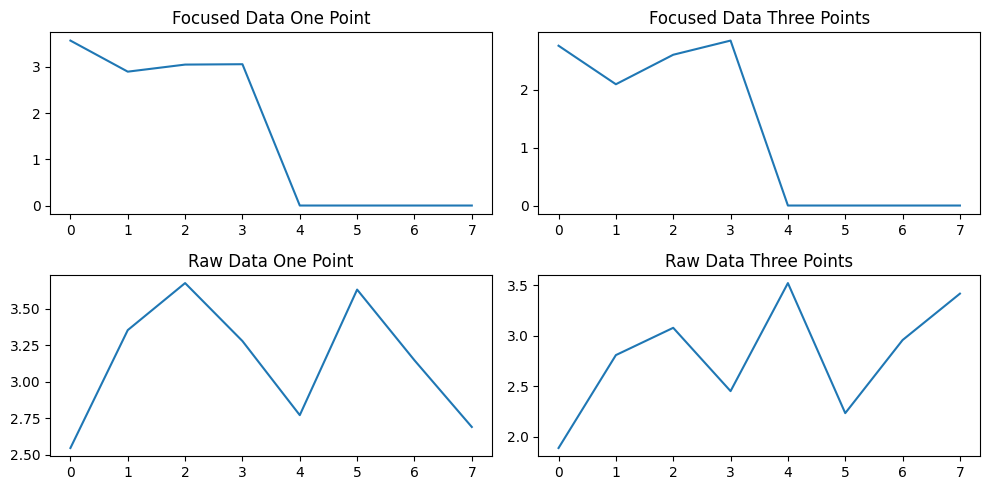

In [18]:
fig, axs = plt.subplots(2,2, figsize=(10,5))
axs[0,0].plot( X_focused[y_arr==1][:1,:].T)
axs[0,0].set_title("Focused Data One Point")
axs[1,0].plot( X_raw[y_arr==1][:1,:].T)
axs[1,0].set_title("Raw Data One Point")

axs[0,1].plot(X_focused[y_arr==0][:1,:].T)
axs[0,1].set_title("Focused Data Three Points")
axs[1,1].plot( X_raw[y_arr==0][:1,:].T)
axs[1,1].set_title("Raw Data Three Points")
plt.tight_layout()
plt.show()  

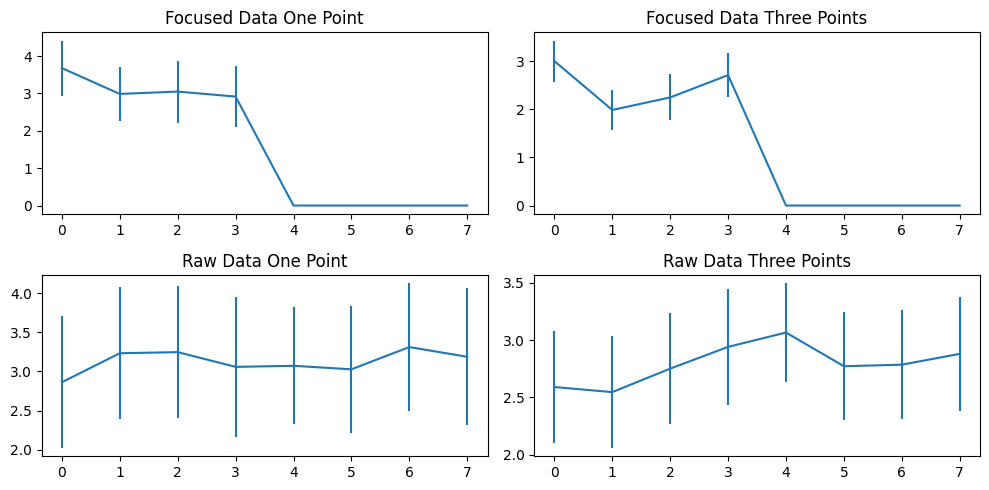

In [19]:
fig, axs = plt.subplots(2,2, figsize=(10,5))
axs[0,0].errorbar(range(8), np.mean(X_focused[y_arr==1], axis=0), yerr=np.std(X_focused[y_arr==1], axis=0))
axs[0,0].set_title("Focused Data One Point")
axs[1,0].errorbar(range(8), np.mean(X_raw[y_arr==1], axis=0), yerr=np.std(X_raw[y_arr==1], axis=0))
axs[1,0].set_title("Raw Data One Point")

axs[0,1].errorbar(range(8), np.mean(X_focused[y_arr==0], axis=0), yerr=np.std(X_focused[y_arr==0], axis=0))
axs[0,1].set_title("Focused Data Three Points")
axs[1,1].errorbar(range(8), np.mean(X_raw[y_arr==0], axis=0), yerr=np.std(X_raw[y_arr==0], axis=0))
axs[1,1].set_title("Raw Data Three Points")
plt.tight_layout()
plt.show()  

In [20]:
clf = LogisticRegression(max_iter=1000)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scores = cross_val_score(clf, X_focused, y_arr, cv=cv, scoring="accuracy", n_jobs=-1)
print(f"Focused 5-fold accuracy: {scores.mean():.3f} ± {scores.std():.3f}")


clf = LogisticRegression(max_iter=1000)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scores = cross_val_score(clf, X_raw, y_arr, cv=cv, scoring="accuracy", n_jobs=-1)
print(f"Raw 5-fold accuracy: {scores.mean():.3f} ± {scores.std():.3f}")

Focused 5-fold accuracy: 0.828 ± 0.002
Raw 5-fold accuracy: 0.835 ± 0.002


In [21]:
clf = GradientBoostingClassifier()
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scores = cross_val_score(clf, X_focused, y_arr, cv=cv, scoring="accuracy", n_jobs=-1)
print(f"Focused 5-fold accuracy: {scores.mean():.3f} ± {scores.std():.3f}")


clf = GradientBoostingClassifier()
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scores = cross_val_score(clf, X_raw, y_arr, cv=cv, scoring="accuracy", n_jobs=-1)
print(f"Raw 5-fold accuracy: {scores.mean():.3f} ± {scores.std():.3f}")

Focused 5-fold accuracy: 0.857 ± 0.001
Raw 5-fold accuracy: 0.919 ± 0.002


LEARNING CURVE ANALYSIS


KeyboardInterrupt: 

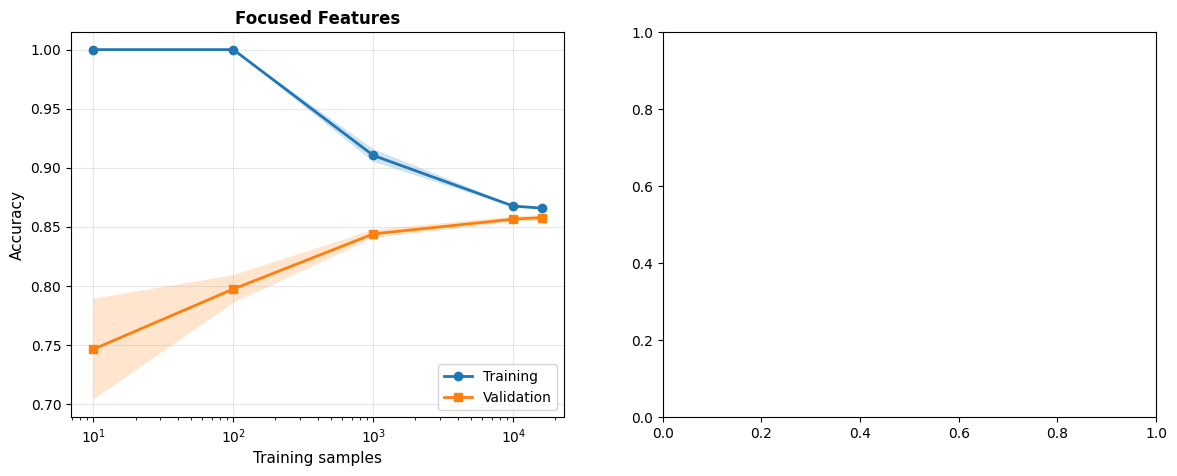

In [22]:
# Define sample sizes to evaluate (logarithmic spacing for efficiency)
train_sizes = np.array([10, 100, 1000, 10000, 16000])

def plot_learning_curves(X, y, feature_name, ax):
    """Generate learning curve showing train/validation performance vs sample size"""
    
    clf = GradientBoostingClassifier(random_state=42)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    # Compute learning curve
    train_sizes_abs, train_scores, val_scores = learning_curve(
        clf, X, y, 
        train_sizes=train_sizes,
        cv=cv, 
        scoring='accuracy',
        n_jobs=-1,
        random_state=42
    )
    
    # Calculate means and standard deviations
    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)
    val_mean = val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)
    
    # Plot
    ax.plot(train_sizes_abs, train_mean, 'o-', label='Training', linewidth=2)
    ax.fill_between(train_sizes_abs, train_mean - train_std, train_mean + train_std, alpha=0.2)
    
    ax.plot(train_sizes_abs, val_mean, 's-', label='Validation', linewidth=2)
    ax.fill_between(train_sizes_abs, val_mean - val_std, val_mean + val_std, alpha=0.2)
    
    # Formatting
    ax.set_xlabel('Training samples', fontsize=11)
    ax.set_ylabel('Accuracy', fontsize=11)
    ax.set_title(f'{feature_name} Features', fontsize=12, fontweight='bold')
    ax.legend(loc='lower right')
    ax.grid(True, alpha=0.3)
    ax.set_xscale('log')
    # ax.set_yscale('log')
    
    # Calculate generalization gap at full data
    gap = train_mean[-1] - val_mean[-1]
    
    return {
        'train_scores': train_mean,
        'val_scores': val_mean,
        'train_std': train_std,
        'val_std': val_std,
        'final_train': train_mean[-1],
        'final_val': val_mean[-1],
        'gap': gap
    }

# Create figure
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Generate curves for both feature sets
print("="*60)
print("LEARNING CURVE ANALYSIS")
print("="*60)

results_focused = plot_learning_curves(X_focused, y_arr, 'Focused', axes[0])
results_raw = plot_learning_curves(X_raw, y_arr, 'Raw', axes[1])

plt.tight_layout()
plt.show()

In [40]:
nsteps = 8 
F_arr = np.tile(np.arange(0, nsteps) / nsteps, (len(X_raw), 1))


# Create sample data (replace with your actual data)
np.random.seed(42)

# Convert to PennyLane arrays
X_raw = pp.array(X_raw, requires_grad=False)
y_arr = pp.array(y_arr, requires_grad=False)

# Create configuration
config = PQCConfig(
    n_qubits=8,
    n_layers=3,
    n_epochs=200,
    batch_size=128,  # Full batch
    learning_rate=0.01,
    optimizer="adam",
    n_folds=2,
    patience=50,
    min_improvement=0.01,
    max_samples=200,  # 0 for using all data
    log_interval=10
)

# Initialize and train classifier
# classifier = PQCClassifier(config)
# history = classifier.train(X_raw, y_arr)
classifier = PQCClassifier(config, use_double_reuploading=True)
history = classifier.train((X_raw, F_arr), y_arr)  

# Access results
for fold_metrics in history['fold_metrics']:
    print(f"Fold {fold_metrics['fold']}: Accuracy = {fold_metrics['final_acc']:.4f}")


Starting 2-Fold Cross-Validation
Mode: Double Data Reuploading
Dataset size: 20000 samples

Training Fold 1/2


Fold 1:   5%|▌         | 10/200 [01:42<31:58, 10.10s/it]

  Epoch 10/200 - Train Loss: 0.6705, Val Loss: 0.6839, Train Acc: 0.6000, Val Acc: 0.5600


Fold 1:  10%|█         | 20/200 [03:51<40:32, 13.51s/it]

  Epoch 20/200 - Train Loss: 0.6429, Val Loss: 0.6689, Train Acc: 0.7050, Val Acc: 0.5700


...

Fold 2:  30%|███       | 60/200 [09:47<24:31, 10.51s/it]

  Epoch 60/200 - Train Loss: 0.5961, Val Loss: 0.6316, Train Acc: 0.7350, Val Acc: 0.6700


Fold 2:  32%|███▏      | 63/200 [10:26<22:41,  9.94s/it]

  Early stopping triggered at epoch 64

Evaluating on validation set...


Fold 2 Final Accuracy: 0.7300

Training Complete!
Mean Accuracy: 0.7150 ± 0.0150
Best Fold Accuracy: 0.7300
Worst Fold Accuracy: 0.7000
Fold 1: Accuracy = 0.7000
Fold 2: Accuracy = 0.7300


In [34]:
pp.random.randn(3,8).flatten().shape

(24,)

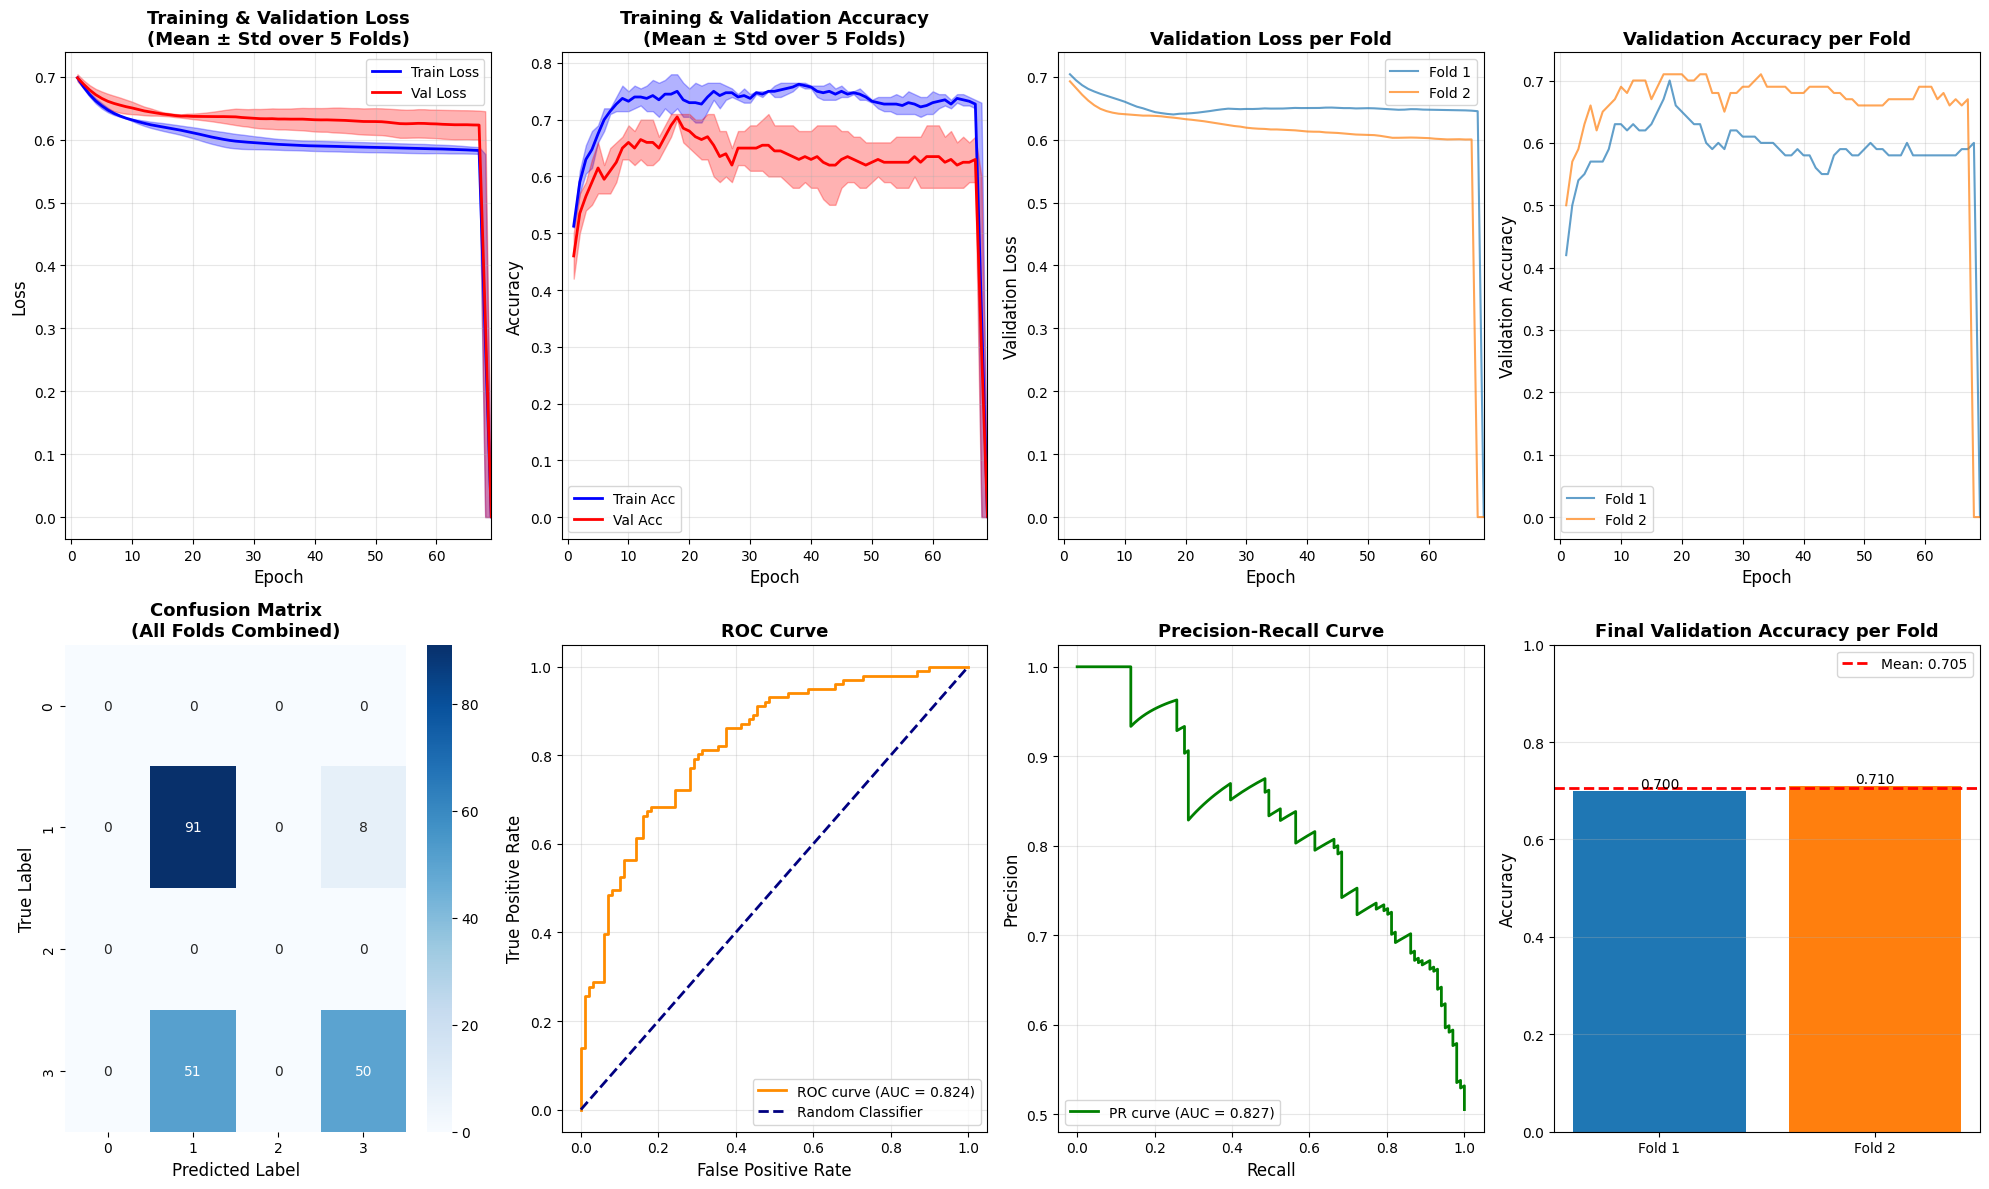


SUMMARY STATISTICS
Mean Validation Accuracy: 0.7050 ± 0.0050
Best Fold Accuracy: 0.7100
Worst Fold Accuracy: 0.7000
ROC-AUC Score: 0.8244
PR-AUC Score: 0.8266


In [38]:
plot_performance(history, config.n_epochs, config.n_folds)

In [ ]:
model

NameError: name 'model' is not defined

In [ ]:
# Create sample data (replace with your actual data)
np.random.seed(42)

# Convert to PennyLane arrays
X_raw = pp.array(X_raw, requires_grad=False)
y_arr = pp.array(y_arr, requires_grad=False)

# Create configuration
config = PQCConfig(
    n_qubits=8,
    n_layers=3,
    n_epochs=200,
    batch_size=0,  # Full batch
    learning_rate=0.01,
    optimizer="adam",
    n_folds=2,
    patience=50,
    min_improvement=0.01,
    max_samples=100,  # Use all data
    log_interval=10
)

# Initialize and train classifier
classifier = PQCClassifier(config)
history = classifier.train(X_raw, y_arr)

# Access results
for fold_metrics in history['fold_metrics']:
    print(f"Fold {fold_metrics['fold']}: Accuracy = {fold_metrics['final_acc']:.4f}")


Starting 2-Fold Cross-Validation
Dataset size: 20000 samples

Training Fold 1/2


Fold 1:   5%|▌         | 10/200 [00:30<09:03,  2.86s/it]

  Epoch 10/200 - Train Loss: 0.6224, Val Loss: 0.6743, Train Acc: 0.7000, Val Acc: 0.5600


Fold 1:  10%|█         | 20/200 [00:59<08:59,  3.00s/it]

  Epoch 20/200 - Train Loss: 0.5954, Val Loss: 0.6553, Train Acc: 0.6700, Val Acc: 0.5600


...

  Epoch 20/200 - Train Loss: 0.6405, Val Loss: 0.6515, Train Acc: 0.6700, Val Acc: 0.6100


Fold 2:  15%|█▌        | 30/200 [15:55:37<11:21:38, 240.58s/it]  

  Epoch 30/200 - Train Loss: 0.6176, Val Loss: 0.6314, Train Acc: 0.6400, Val Acc: 0.6000


Fold 2:  18%|█▊        | 36/200 [15:55:55<72:34:46, 1593.21s/it]


KeyboardInterrupt: 

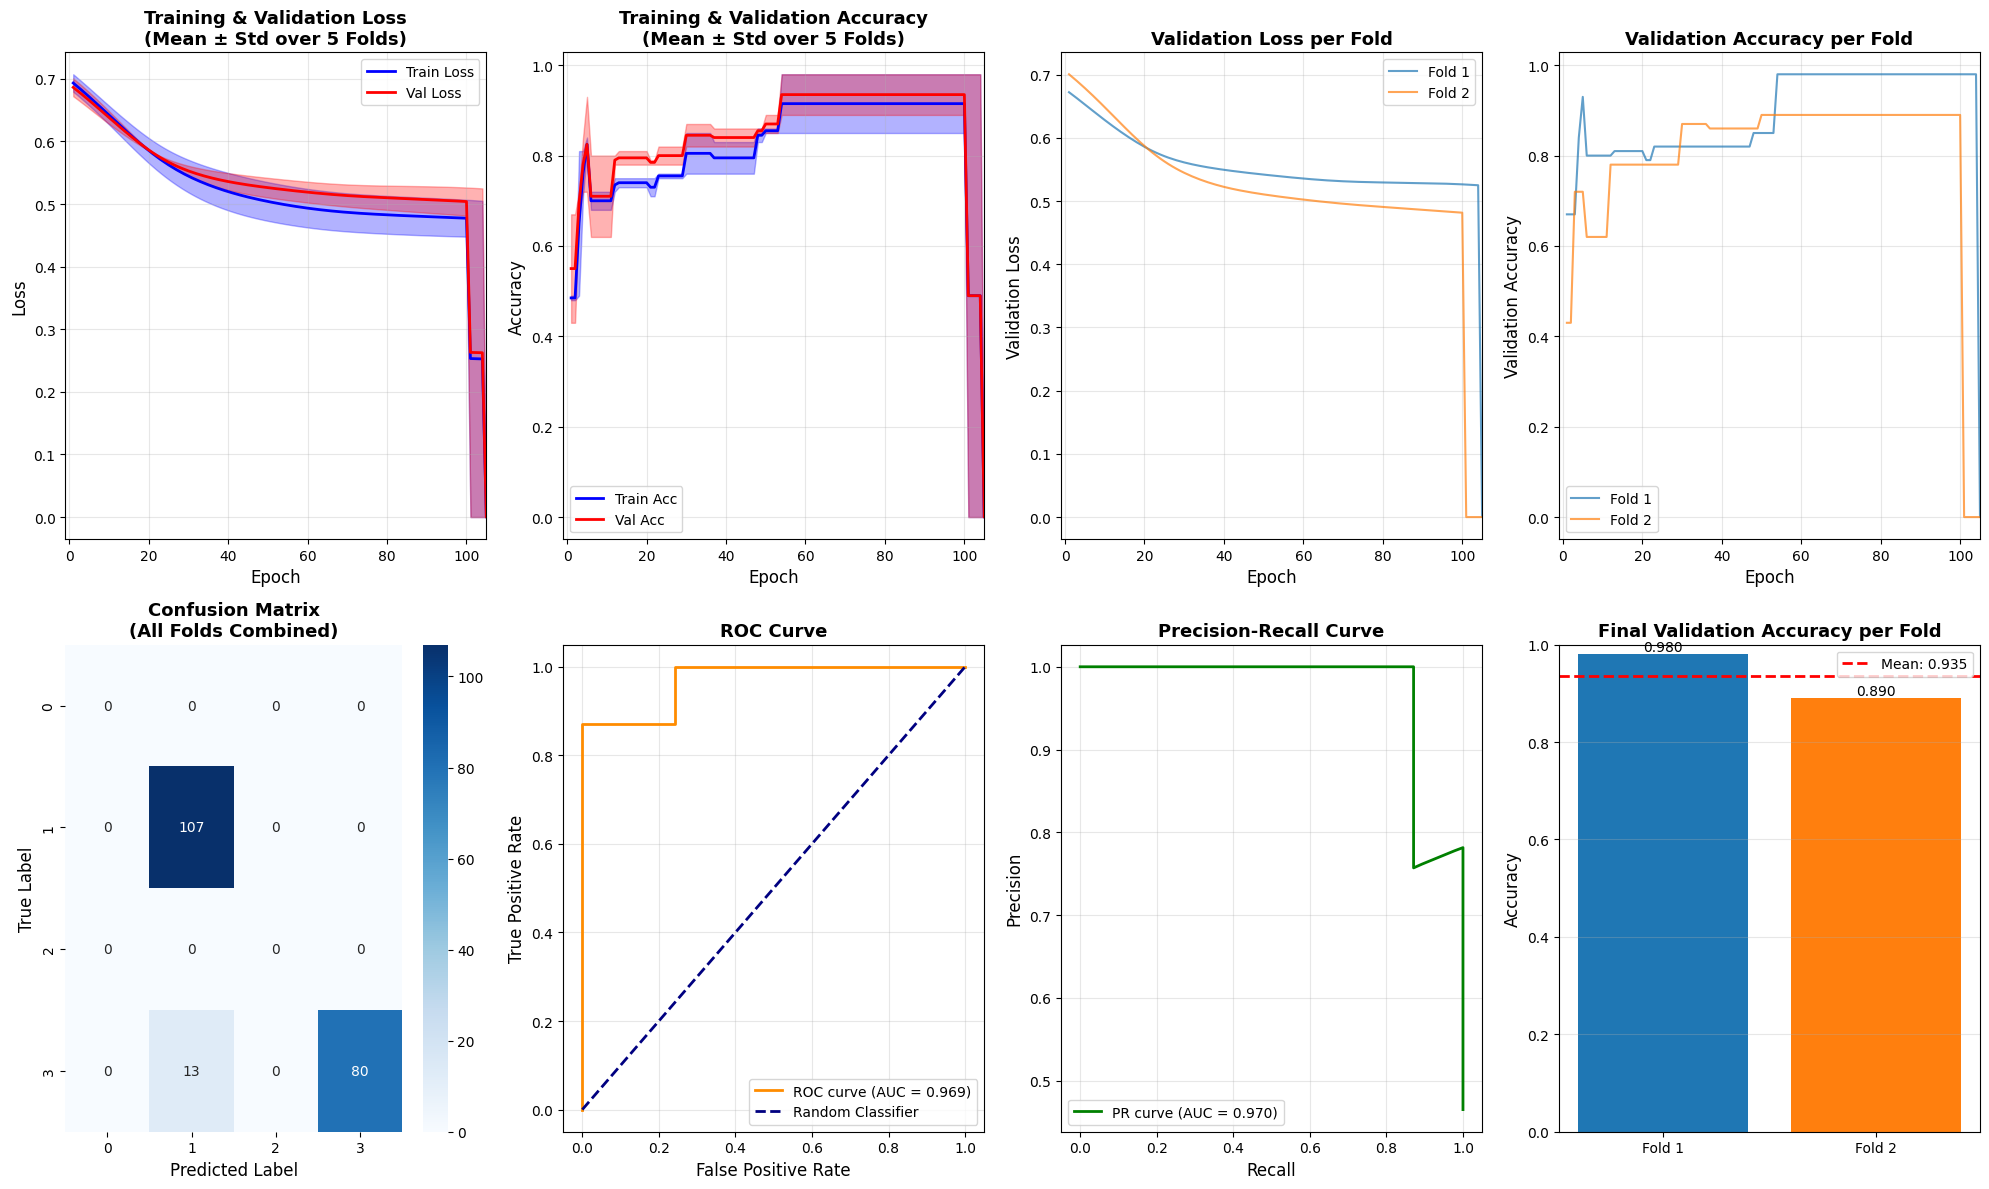


SUMMARY STATISTICS
Mean Validation Accuracy: 0.9350 ± 0.0450
Best Fold Accuracy: 0.9800
Worst Fold Accuracy: 0.8900
ROC-AUC Score: 0.9686
PR-AUC Score: 0.9703


In [ ]:
plot_performance(history, config.n_epochs, config.n_folds)

In [ ]:
stop

In [ ]:
# Create sample data (replace with your actual data)
np.random.seed(42)

# Convert to PennyLane arrays
X_focused = pp.array(X_focused, requires_grad=False)

# Create configuration
config = PQCConfig(
    n_qubits=8,
    n_layers=3,
    n_epochs=200,
    batch_size=0,  # Full batch
    learning_rate=0.01,
    optimizer="adam",
    n_folds=2,
    patience=50,
    min_improvement=0.01,
    max_samples=100,  # Use all data
    log_interval=10
)

# Initialize and train classifier
classifier = PQCClassifier(config)
history = classifier.train(X_focused, y_arr)

# Access results
for fold_metrics in history['fold_metrics']:
    print(f"Fold {fold_metrics['fold']}: Accuracy = {fold_metrics['final_acc']:.4f}")


Starting 2-Fold Cross-Validation
Dataset size: 20000 samples

Training Fold 1/2


Fold 1:   5%|▌         | 10/200 [00:30<08:47,  2.78s/it]

  Epoch 10/200 - Train Loss: 0.5846, Val Loss: 0.5908, Train Acc: 0.9700, Val Acc: 0.9600


Fold 1:  10%|█         | 20/200 [00:58<07:50,  2.61s/it]

  Epoch 20/200 - Train Loss: 0.5521, Val Loss: 0.5536, Train Acc: 0.9700, Val Acc: 0.9600


Fold 1:  15%|█▌        | 30/200 [01:28<08:19,  2.94s/it]

  Epoch 30/200 - Train Loss: 0.5275, Val Loss: 0.5243, Train Acc: 0.9700, Val Acc: 0.9600


Fold 1:  20%|██        | 40/200 [01:56<07:50,  2.94s/it]

  Epoch 40/200 - Train Loss: 0.5057, Val Loss: 0.5006, Train Acc: 0.9700, Val Acc: 0.9600


Fold 1:  22%|██▏       | 43/200 [02:08<08:45,  3.35s/it]

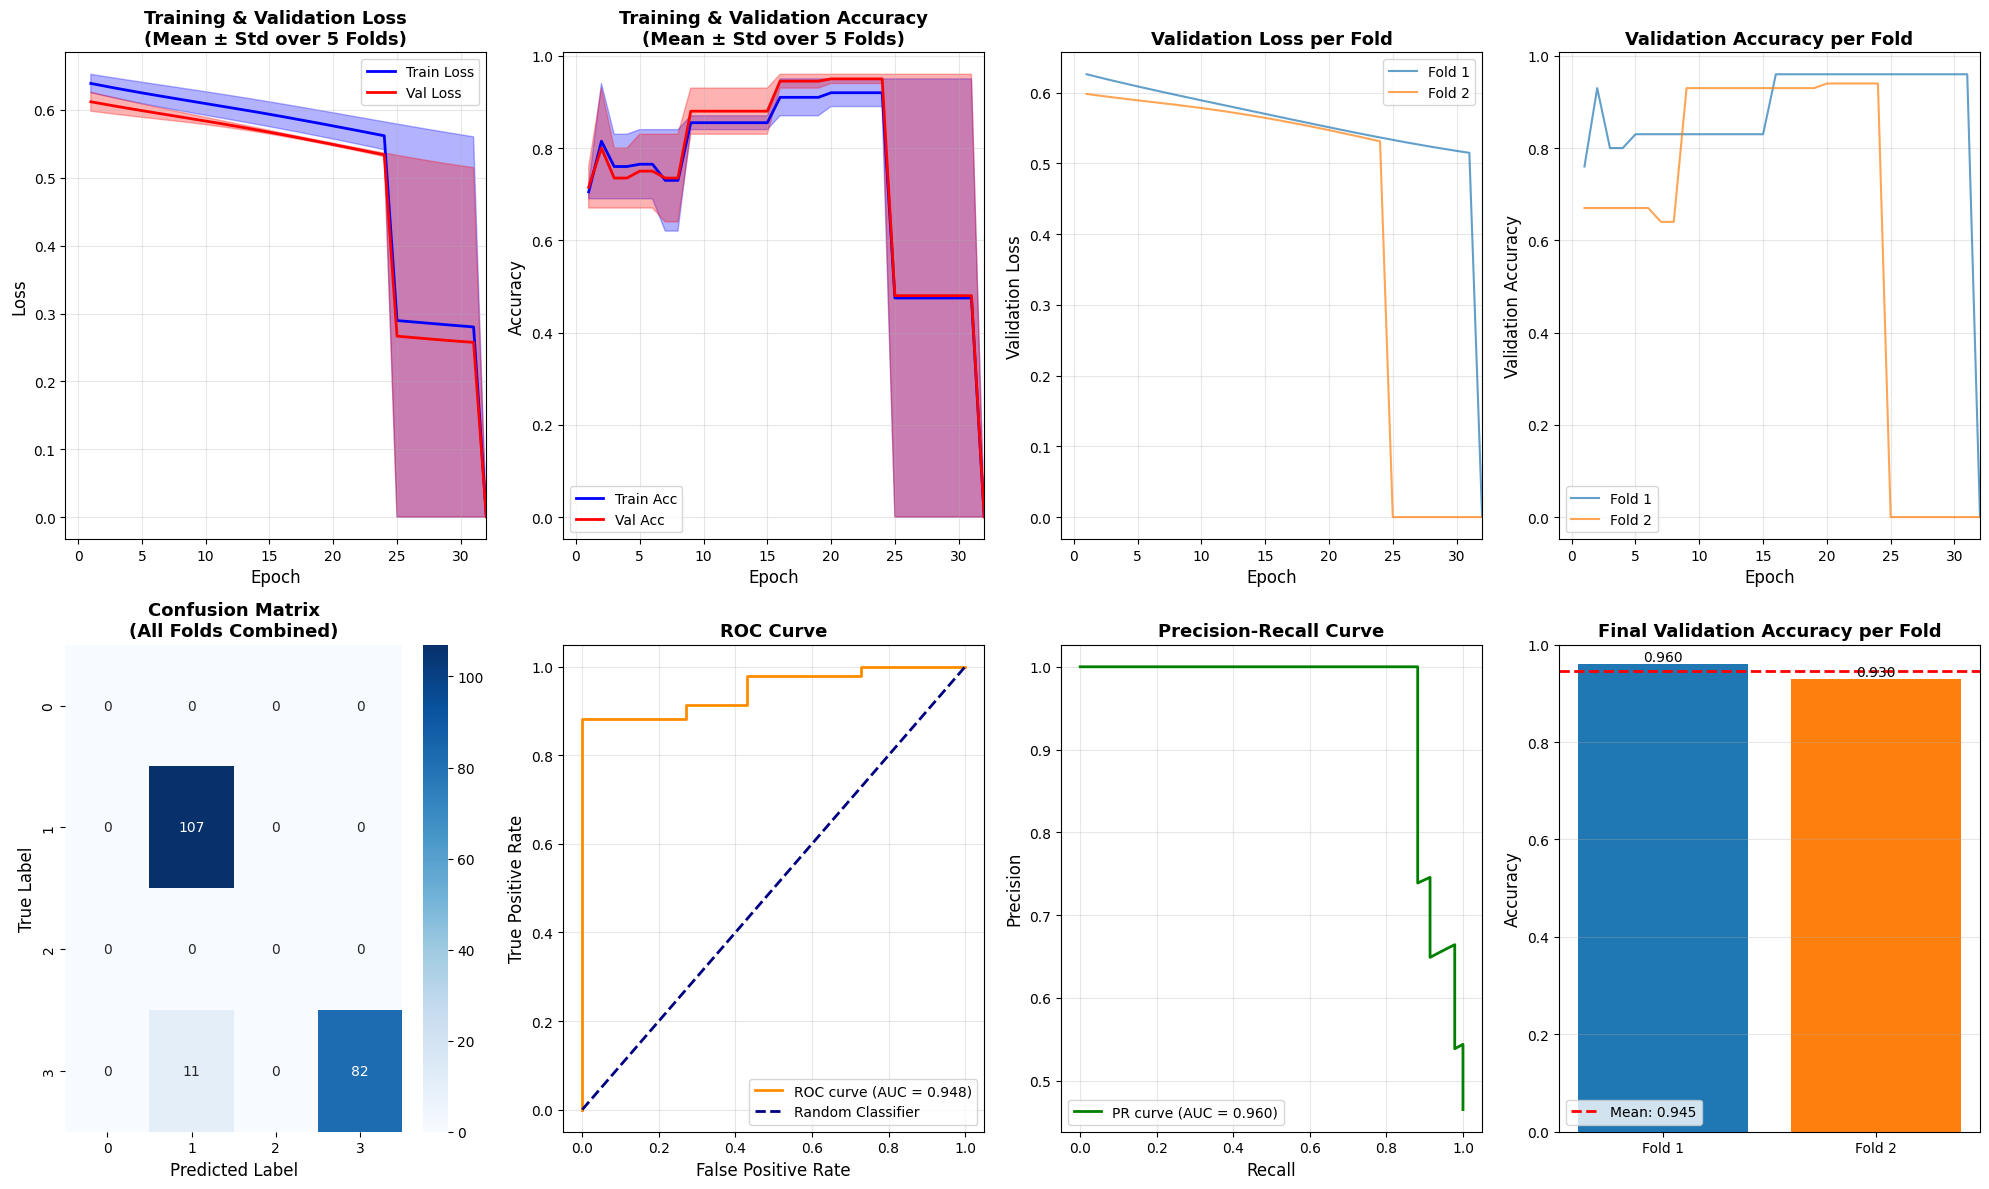


SUMMARY STATISTICS
Mean Validation Accuracy: 0.9450 ± 0.0150
Best Fold Accuracy: 0.9600
Worst Fold Accuracy: 0.9300
ROC-AUC Score: 0.9478
PR-AUC Score: 0.9597


In [ ]:
plot_performance(history, config.n_epochs, config.n_folds)

In [2]:
300*15/2

2250.0

In [3]:
adSampling      = 1e6;     	
chirpLength     = 1e-6;   
		
	
xs = 2;     
ys = 2;     
if xs <= round(chirpLength * adSampling / 2):
    print('\n ERROR: array size is smaller than chirp length, %d vs. %d', xs, round(chirpLength * adSampling / 2));